In [ ]:
## Plant Identification using Deep Learning (ConvNeXtV2)

# ==========================================================
# SECTION 1 : ENVIRONMENT SETUP
# ==========================================================

# ==========================================================
# Install Required Libraries
# ==========================================================

!pip -q install -U timm albumentations kagglehub grad-cam torchmetrics

# ==========================================================
# Imports
# ==========================================================

import os
import gc
import cv2
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ==========================================================
# Reproducibility
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ==========================================================
# CUDA Optimizations
# ==========================================================

cudnn.benchmark = True
cudnn.enabled = True

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# ==========================================================
# GPU
# ==========================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*70)
print("DEVICE :", device)

if torch.cuda.is_available():

    print("GPU :", torch.cuda.get_device_name(0))

    print("CUDA :", torch.version.cuda)

    print("GPU Memory : {:.2f} GB".format(
        torch.cuda.get_device_properties(0).total_memory/1024**3
    ))

print("="*70)

# ==========================================================
# DataLoader Configuration
# ==========================================================

CPU_CORES = os.cpu_count()

NUM_WORKERS = min(8, CPU_CORES)

PIN_MEMORY = True

PERSISTENT_WORKERS = True

PREFETCH_FACTOR = 4

print("CPU Cores :", CPU_CORES)

print("Workers :", NUM_WORKERS)

# ==========================================================
# Image Configuration
# ==========================================================

IMAGE_SIZE = 224

BATCH_SIZE = 128

NUM_EPOCHS = 35

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

print("="*70)

print("Image Size :", IMAGE_SIZE)

print("Batch Size :", BATCH_SIZE)

print("Epochs :", NUM_EPOCHS)

print("="*70)

# ==========================================================
# Clear Memory
# ==========================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

# ==========================================================
# Environment Ready
# ==========================================================

print("\nEnvironment Ready Successfully.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
DEVICE : cpu
CPU Cores : 2
Workers : 2
Image Size : 224
Batch Size : 128
Epochs : 35

Environment Ready Successfully.


Using Colab cache for faster access to the 'leafsnap-dataset' dataset.

Dataset Downloaded Successfully!
/kaggle/input/leafsnap-dataset

Dataset Used : field


  0%|          | 0/184 [00:00<?, ?it/s]

Dataset Loaded
                                               image           label
0  /kaggle/input/leafsnap-dataset/leafsnap-datase...  abies_concolor
1  /kaggle/input/leafsnap-dataset/leafsnap-datase...  abies_concolor
2  /kaggle/input/leafsnap-dataset/leafsnap-datase...  abies_concolor
3  /kaggle/input/leafsnap-dataset/leafsnap-datase...  abies_concolor
4  /kaggle/input/leafsnap-dataset/leafsnap-datase...  abies_concolor

Total Images : 7719
Total Classes : 184

Checking images...


  0%|          | 0/7719 [00:00<?, ?it/s]


Valid Images : 7719

Average Images/Class : 41.95
Minimum Images/Class : 10
Maximum Images/Class : 183


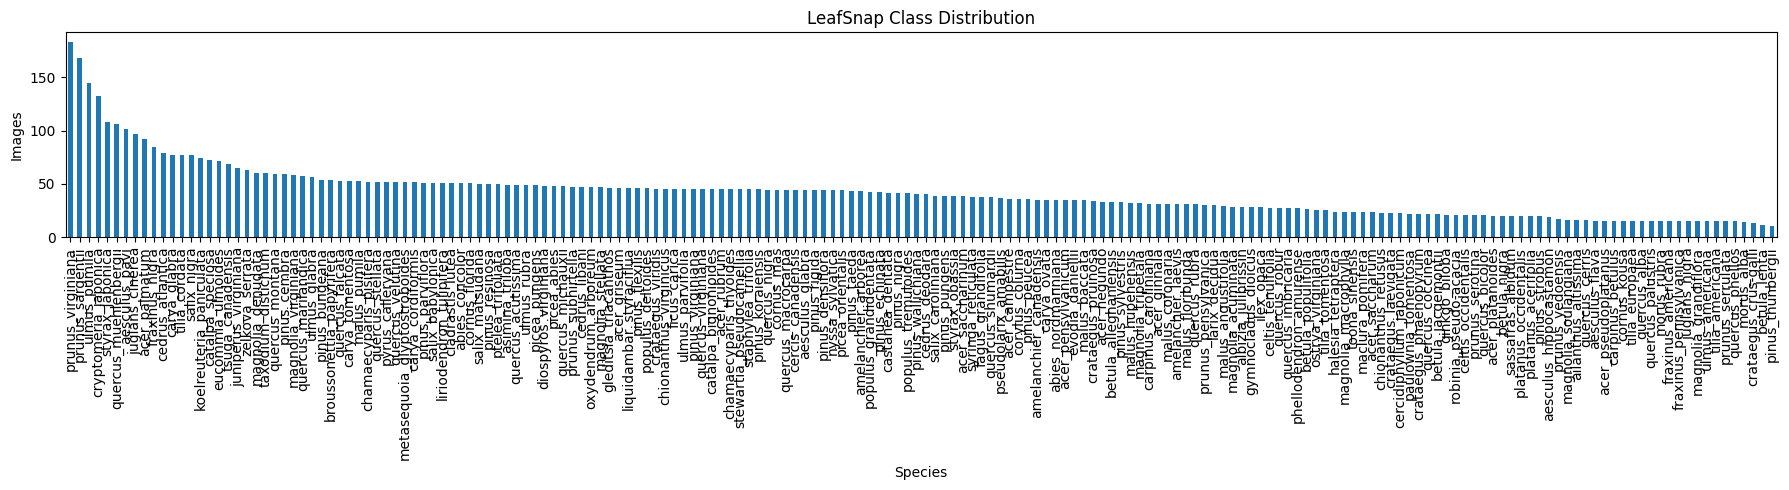

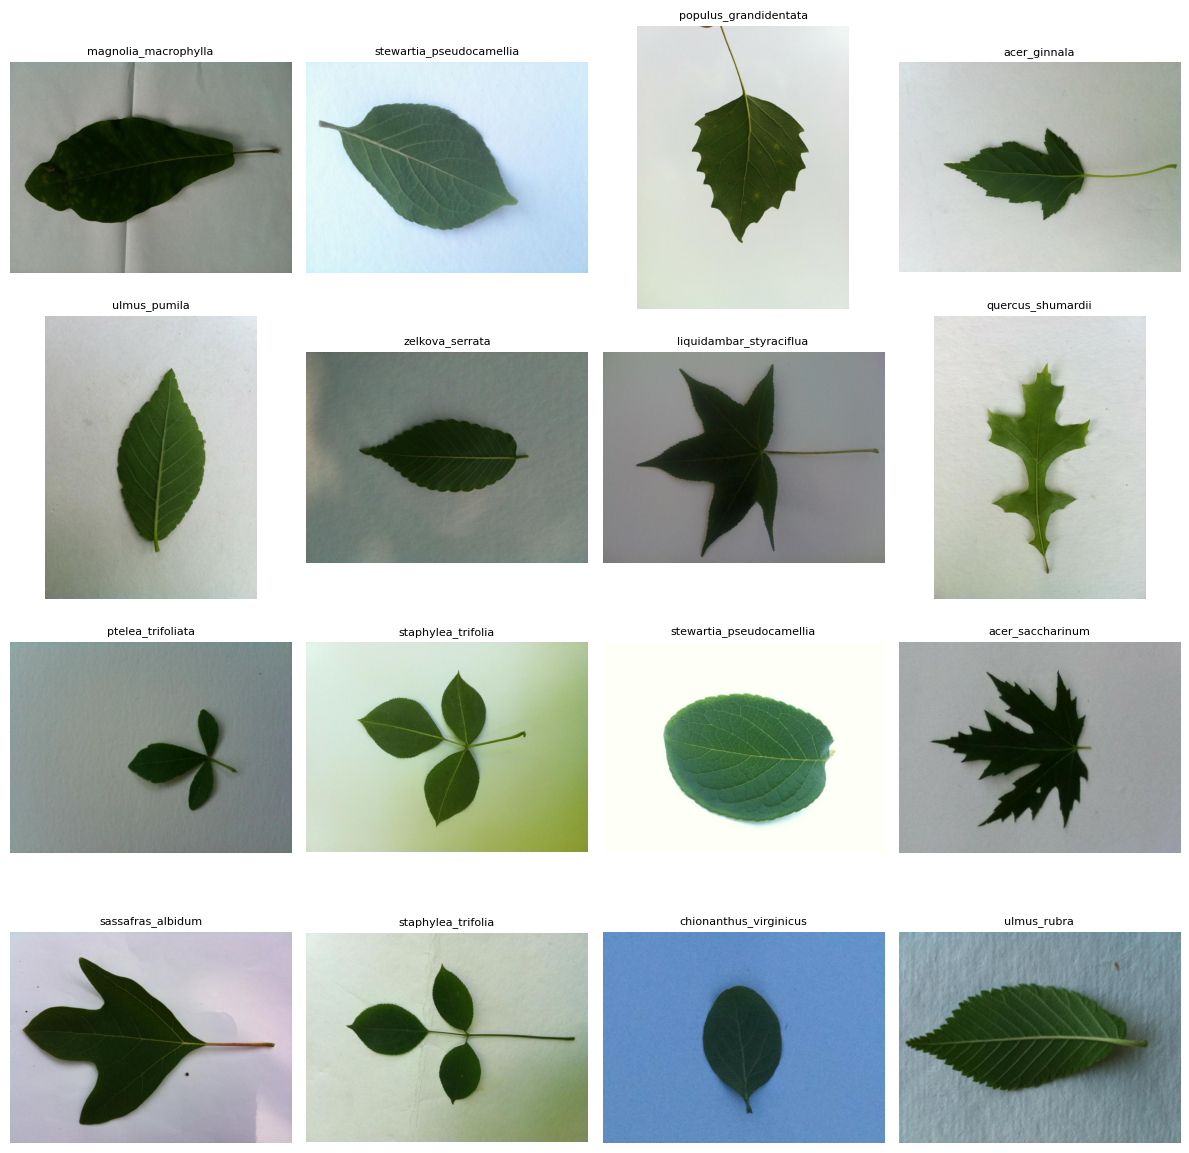

Section 2 Completed Successfully


In [ ]:
# ==========================================================
# SECTION 2 : DOWNLOAD & ANALYZE DATASET
# ==========================================================

import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt

print("="*70)
print("Downloading LeafSnap Dataset...")
print("="*70)

# ----------------------------------------------------------
# Download Dataset
# ----------------------------------------------------------

dataset_path = kagglehub.dataset_download(
    "xhlulu/leafsnap-dataset"
)

print("\nDataset Downloaded Successfully!")
print(dataset_path)

# ----------------------------------------------------------
# Select Dataset
# ----------------------------------------------------------

# Options:
# "field"  -> Original field images
# "lab"    -> Laboratory images

DATASET_TYPE = "field"

IMAGE_ROOT = os.path.join(
    dataset_path,
    "leafsnap-dataset",
    "dataset",
    "images",
    DATASET_TYPE
)

assert os.path.exists(IMAGE_ROOT), "Dataset folder not found."

print("\nDataset Used :", DATASET_TYPE)

# ----------------------------------------------------------
# Read Dataset
# ----------------------------------------------------------

image_paths = []
labels = []

species = sorted(os.listdir(IMAGE_ROOT))

for cls in tqdm(species):

    cls_path = os.path.join(IMAGE_ROOT, cls)

    if not os.path.isdir(cls_path):
        continue

    for img in os.listdir(cls_path):

        if img.lower().endswith((".jpg",".jpeg",".png")):

            image_paths.append(
                os.path.join(cls_path,img)
            )

            labels.append(cls)

df = pd.DataFrame({

    "image":image_paths,

    "label":labels

})

print("="*70)

print("Dataset Loaded")

print("="*70)

print(df.head())

print()

print("Total Images :",len(df))

print("Total Classes :",df.label.nunique())

# ----------------------------------------------------------
# Remove Corrupted Images
# ----------------------------------------------------------

print("\nChecking images...")

valid = []

for path in tqdm(df.image):

    img = cv2.imread(path)

    valid.append(img is not None)

df = df[valid].reset_index(drop=True)

print()

print("Valid Images :",len(df))

# ----------------------------------------------------------
# Class Statistics
# ----------------------------------------------------------

class_counts = df.label.value_counts()

print()

print("Average Images/Class :",round(class_counts.mean(),2))

print("Minimum Images/Class :",class_counts.min())

print("Maximum Images/Class :",class_counts.max())

# ----------------------------------------------------------
# Plot Distribution
# ----------------------------------------------------------

plt.figure(figsize=(18,5))

class_counts.plot(kind="bar")

plt.title("LeafSnap Class Distribution")

plt.xlabel("Species")

plt.ylabel("Images")

plt.tight_layout()

plt.show()

# ----------------------------------------------------------
# Show Random Images
# ----------------------------------------------------------

sample = df.sample(16, random_state=SEED)

fig, axes = plt.subplots(4,4,figsize=(12,12))

axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):

    img = cv2.imread(row.image)

    img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

    ax.imshow(img)

    ax.set_title(row.label,fontsize=8)

    ax.axis("off")

plt.tight_layout()

plt.show()

print("="*70)
print("Section 2 Completed Successfully")
print("="*70)

Creating Dataset Splits
Number of Classes : 184

Dataset Split Summary
Training Images   : 5403
Validation Images : 1158
Testing Images    : 1158

Training %   : 70.00%
Validation % : 15.00%
Testing %    : 15.00%

Class Verification
Train Classes : 184
Validation Classes : 184
Test Classes : 184

All classes are present in every split.

CSV Files Saved
train.csv
val.csv
test.csv


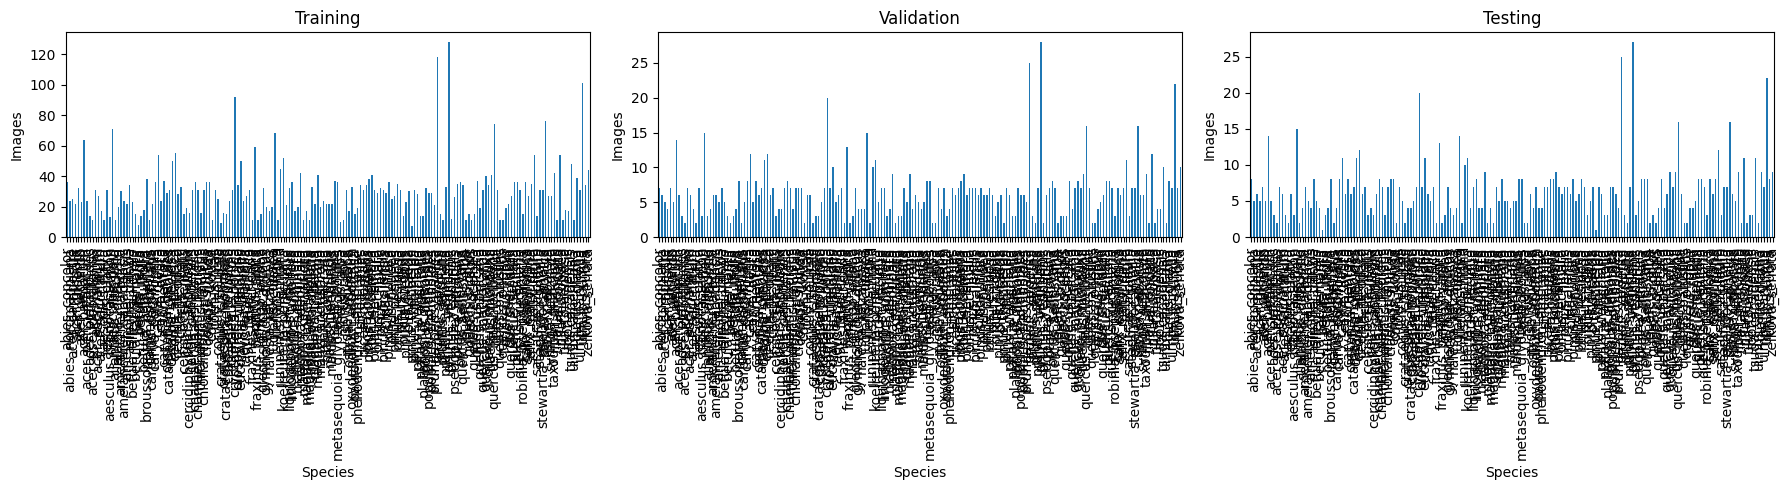

Section 3 Completed Successfully


In [ ]:
# ==========================================================
# SECTION 3 : TRAIN / VALIDATION / TEST SPLIT
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("="*70)
print("Creating Dataset Splits")
print("="*70)

# ----------------------------------------------------------
# Split Ratio
# ----------------------------------------------------------

TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15

# ----------------------------------------------------------
# Label Encoding
# ----------------------------------------------------------

label_encoder = LabelEncoder()

df["label_encoded"] = label_encoder.fit_transform(df["label"])

NUM_CLASSES = len(label_encoder.classes_)

print("Number of Classes :", NUM_CLASSES)

# Dictionary for prediction

idx_to_class = {
    i: c for i, c in enumerate(label_encoder.classes_)
}

class_to_idx = {
    c: i for i, c in enumerate(label_encoder.classes_)
}

# ----------------------------------------------------------
# Train Split (70%)
# ----------------------------------------------------------

train_df, temp_df = train_test_split(

    df,

    train_size=TRAIN_SIZE,

    stratify=df["label_encoded"],

    random_state=SEED

)

# ----------------------------------------------------------
# Validation/Test Split (15% / 15%)
# ----------------------------------------------------------

val_df, test_df = train_test_split(

    temp_df,

    test_size=0.50,

    stratify=temp_df["label_encoded"],

    random_state=SEED

)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ----------------------------------------------------------
# Display Statistics
# ----------------------------------------------------------

print()

print("="*70)

print("Dataset Split Summary")

print("="*70)

print(f"Training Images   : {len(train_df)}")
print(f"Validation Images : {len(val_df)}")
print(f"Testing Images    : {len(test_df)}")

print()

print(f"Training %   : {len(train_df)/len(df)*100:.2f}%")
print(f"Validation % : {len(val_df)/len(df)*100:.2f}%")
print(f"Testing %    : {len(test_df)/len(df)*100:.2f}%")

# ----------------------------------------------------------
# Verify Every Class Exists
# ----------------------------------------------------------

print()

print("="*70)

print("Class Verification")

print("="*70)

print("Train Classes :", train_df["label"].nunique())
print("Validation Classes :", val_df["label"].nunique())
print("Test Classes :", test_df["label"].nunique())

assert train_df["label"].nunique() == NUM_CLASSES
assert val_df["label"].nunique() == NUM_CLASSES
assert test_df["label"].nunique() == NUM_CLASSES

print("\nAll classes are present in every split.")

# ----------------------------------------------------------
# Save CSV Files
# ----------------------------------------------------------

train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)

print()

print("CSV Files Saved")

print("train.csv")
print("val.csv")
print("test.csv")

# ----------------------------------------------------------
# Class Distribution
# ----------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,3, figsize=(18,5))

train_df["label"].value_counts().sort_index().plot(
    kind="bar",
    ax=ax[0],
    title="Training"
)

val_df["label"].value_counts().sort_index().plot(
    kind="bar",
    ax=ax[1],
    title="Validation"
)

test_df["label"].value_counts().sort_index().plot(
    kind="bar",
    ax=ax[2],
    title="Testing"
)

for a in ax:
    a.set_xlabel("Species")
    a.set_ylabel("Images")

plt.tight_layout()
plt.show()

print("="*70)
print("Section 3 Completed Successfully")
print("="*70)

In [ ]:
# ==========================================================
# SECTION 4 : DATASET & HIGH PERFORMANCE DATALOADER
# ==========================================================

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image, ImageReadMode
import torchvision.transforms.functional as F
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ==========================================================
# Image Configuration
# ==========================================================

IMAGE_SIZE = 224

# ==========================================================
# Training Augmentations
# ==========================================================

train_transform = A.Compose([

    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.75, 1.0),
        ratio=(0.9, 1.1)
    ),

    A.HorizontalFlip(p=0.5),

    A.Rotate(
        limit=20,
        p=0.5,
        border_mode=cv2.BORDER_REFLECT
    ),

    A.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.20,
        hue=0.10,
        p=0.5
    ),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

# ==========================================================
# Validation / Test
# ==========================================================

valid_transform = A.Compose([

    A.Resize(256,256),

    A.CenterCrop(224,224),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

# ==========================================================
# Dataset
# ==========================================================

class LeafDataset(Dataset):

    def __init__(self, dataframe, transform):

        self.df = dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = read_image(
            row.image,
            mode=ImageReadMode.RGB
        )

        image = image.permute(1,2,0).numpy()

        image = self.transform(
            image=image
        )["image"]

        label = int(row.label_encoded)

        return image, label

# ==========================================================
# Dataset Objects
# ==========================================================

train_dataset = LeafDataset(
    train_df,
    train_transform
)

val_dataset = LeafDataset(
    val_df,
    valid_transform
)

test_dataset = LeafDataset(
    test_df,
    valid_transform
)

print("Train :",len(train_dataset))
print("Validation :",len(val_dataset))
print("Test :",len(test_dataset))

# ==========================================================
# DataLoaders
# ==========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=True,

    persistent_workers=True,

    prefetch_factor=4,

    drop_last=True

)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=True,

    persistent_workers=True,

    prefetch_factor=4

)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=True,

    persistent_workers=True,

    prefetch_factor=4

)

# ==========================================================
# Test DataLoader
# ==========================================================

images, labels = next(iter(train_loader))

print("="*60)

print("Batch Shape :", images.shape)

print("Labels :", labels.shape)

print("Image dtype :", images.dtype)

print("="*60)

Train : 5403
Validation : 1158
Test : 1158
Batch Shape : torch.Size([128, 3, 224, 224])
Labels : torch.Size([128])
Image dtype : torch.float32


In [ ]:
# ==========================================================
# SECTION 5 : ConvNeXt V2 Tiny
# ==========================================================

import timm
import torch
import torch.nn as nn

print("="*70)
print("Loading ConvNeXt V2 Tiny")
print("="*70)

MODEL_NAME = "convnextv2_tiny.fcmae_ft_in22k_in1k"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)

# ---------------------------------------------------------
# Freeze everything
# ---------------------------------------------------------

for p in model.parameters():
    p.requires_grad = False

# ---------------------------------------------------------
# Fine-tune last TWO stages
# ---------------------------------------------------------

for p in model.stages[2].parameters():
    p.requires_grad = True

for p in model.stages[3].parameters():
    p.requires_grad = True

# ---------------------------------------------------------
# Final LayerNorm
# ---------------------------------------------------------

if hasattr(model, "norm"):
    for p in model.norm.parameters():
        p.requires_grad = True

# ---------------------------------------------------------
# Replace classifier
# ---------------------------------------------------------

in_features = model.head.fc.in_features

model.head.fc = nn.Sequential(

    nn.Linear(in_features,1024),

    nn.GELU(),

    nn.BatchNorm1d(1024),

    nn.Dropout(0.40),

    nn.Linear(1024,512),

    nn.GELU(),

    nn.BatchNorm1d(512),

    nn.Dropout(0.30),

    nn.Linear(512,NUM_CLASSES)

)

for p in model.head.fc.parameters():
    p.requires_grad = True

model = model.to(device)
model = model.to(memory_format=torch.channels_last)

print(model)

Loading ConvNeXt V2 Tiny


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

ConvNeXt(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): GlobalResponseNormMlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (grn): GlobalResponseNorm()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), 

In [ ]:
# ==========================================================
# SECTION 6 : TRAINING ENGINE
# ==========================================================

import time
import gc

from tqdm.auto import tqdm

import torch
import torch.nn as nn

# ----------------------------------------------------------
# Hyperparameters
# ----------------------------------------------------------

EPOCHS = 35

PATIENCE = 8

BEST_MODEL = "best_convnextv2_leafsnap.pth"

# ----------------------------------------------------------
# Loss
# ----------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# ----------------------------------------------------------
# Optimizer
# ----------------------------------------------------------

optimizer = torch.optim.AdamW(

    [

        {
            "params": model.stages[2].parameters(),
            "lr":5e-6
        },

        {
            "params": model.stages[3].parameters(),
            "lr":1e-5
        },

        {
            "params": model.head.parameters(),
            "lr":3e-4
        }

    ],

    weight_decay=1e-4

)

# ----------------------------------------------------------
# Scheduler
# ----------------------------------------------------------

scheduler = torch.optim.lr_scheduler.OneCycleLR(

    optimizer,

    max_lr=[5e-6,1e-5,3e-4],

    epochs=EPOCHS,

    steps_per_epoch=len(train_loader),

    pct_start=0.15,

    div_factor=25,

    final_div_factor=1000

)

# ----------------------------------------------------------
# AMP
# ----------------------------------------------------------

scaler = torch.amp.GradScaler("cuda")

# ----------------------------------------------------------
# History
# ----------------------------------------------------------

history = {

    "train_loss":[],
    "val_loss":[],
    "train_acc":[],
    "val_acc":[],
    "lr":[]

}

best_acc = 0

patience_counter = 0

# ==========================================================
# TRAINING
# ==========================================================

for epoch in range(EPOCHS):

    gc.collect()

    torch.cuda.empty_cache()

    # --------------------------
    # TRAIN
    # --------------------------

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    train_bar = tqdm(train_loader)

    for images, labels in train_bar:

        images = images.to(
            device,
            non_blocking=True,
            memory_format=torch.channels_last
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        scaler.step(optimizer)

        scaler.update()

        scheduler.step()

        running_loss += loss.item()

        preds = outputs.argmax(1)

        correct += (preds==labels).sum().item()

        total += labels.size(0)

        train_bar.set_description(
            f"Epoch {epoch+1}/{EPOCHS}"
        )

        train_bar.set_postfix(

            loss=f"{loss.item():.4f}",

            acc=f"{100*correct/total:.2f}%"

        )

    train_loss = running_loss / len(train_loader)

    train_acc = correct / total

    # --------------------------
    # VALIDATION
    # --------------------------

    model.eval()

    val_loss = 0

    val_correct = 0

    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True,
                memory_format=torch.channels_last
            )

            labels = labels.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

                loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(1)

            val_correct += (preds==labels).sum().item()

            val_total += labels.size(0)

    val_loss /= len(val_loader)

    val_acc = val_correct / val_total

    current_lr = optimizer.param_groups[-1]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["lr"].append(current_lr)

    print()

    print("="*70)

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print(f"Train Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc*100:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"LR         : {current_lr:.8f}")

    if torch.cuda.is_available():

        print(f"GPU Memory : {torch.cuda.memory_allocated()/1024**3:.2f} GB")

    print("="*70)

    # --------------------------
    # Save Best
    # --------------------------

    if val_acc > best_acc:

        best_acc = val_acc

        patience_counter = 0

        torch.save(model.state_dict(), BEST_MODEL)

        print("Best model saved.")

    else:

        patience_counter += 1

    # --------------------------
    # Early Stop
    # --------------------------

    if patience_counter >= PATIENCE:

        print("Early stopping activated.")

        break

print()

print("="*70)

print(f"Best Validation Accuracy : {best_acc*100:.2f}%")

print("="*70)

  0%|          | 0/42 [00:00<?, ?it/s]

In [ ]:
# ==========================================================
# SECTION 7 : MODEL EVALUATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    top_k_accuracy_score
)

print("="*70)
print("Loading Best Model...")
print("="*70)

# ----------------------------------------------------------
# Load Best Model
# ----------------------------------------------------------

model.load_state_dict(
    torch.load(BEST_MODEL, map_location=device)
)

model.eval()

predictions = []
targets = []
probabilities = []

# ----------------------------------------------------------
# Evaluation
# ----------------------------------------------------------

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(
            device,
            non_blocking=True,
            memory_format=torch.channels_last
        )

        labels = labels.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        preds = torch.argmax(probs, dim=1)

        predictions.extend(preds.cpu().numpy())

        targets.extend(labels.cpu().numpy())

        probabilities.extend(probs.cpu().numpy())

predictions = np.array(predictions)

targets = np.array(targets)

probabilities = np.array(probabilities)

# ----------------------------------------------------------
# Metrics
# ----------------------------------------------------------

accuracy = accuracy_score(targets, predictions)

top5 = top_k_accuracy_score(
    targets,
    probabilities,
    k=5,
    labels=np.arange(NUM_CLASSES)
)

precision = precision_score(
    targets,
    predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    targets,
    predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    targets,
    predictions,
    average="weighted",
    zero_division=0
)

kappa = cohen_kappa_score(
    targets,
    predictions
)

mcc = matthews_corrcoef(
    targets,
    predictions
)

# ----------------------------------------------------------
# Print Results
# ----------------------------------------------------------

print("\n")

print("="*70)

print(f"Top-1 Accuracy : {accuracy*100:.2f}%")

print(f"Top-5 Accuracy : {top5*100:.2f}%")

print(f"Precision      : {precision:.4f}")

print(f"Recall         : {recall:.4f}")

print(f"F1 Score       : {f1:.4f}")

print(f"Cohen Kappa    : {kappa:.4f}")

print(f"MCC            : {mcc:.4f}")

print("="*70)

# ----------------------------------------------------------
# Save Metrics
# ----------------------------------------------------------

metrics = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Top5",

        "Precision",

        "Recall",

        "F1",

        "Kappa",

        "MCC"

    ],

    "Value":[

        accuracy,

        top5,

        precision,

        recall,

        f1,

        kappa,

        mcc

    ]

})

metrics.to_csv(
    "evaluation_metrics.csv",
    index=False
)

# ----------------------------------------------------------
# Classification Report
# ----------------------------------------------------------

report = classification_report(

    targets,

    predictions,

    target_names=label_encoder.classes_,

    output_dict=True,

    zero_division=0

)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(

    "classification_report.csv"

)

print("\nClassification Report Saved")

# ----------------------------------------------------------
# Confusion Matrix
# ----------------------------------------------------------

cm = confusion_matrix(
    targets,
    predictions
)

plt.figure(figsize=(20,18))

sns.heatmap(

    cm,

    cmap="Blues",

    cbar=True,

    xticklabels=False,

    yticklabels=False

)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.show()

print("="*70)
print("Section 7 Completed Successfully")
print("="*70)

In [ ]:
# ==========================================================
# SECTION 8 : TRAINING ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

plt.style.use("ggplot")

# ----------------------------------------------------------
# Loss Curve
# ----------------------------------------------------------

epochs = np.arange(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10,6))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "loss_curve.png",
    dpi=300
)

plt.show()

# ----------------------------------------------------------
# Accuracy Curve
# ----------------------------------------------------------

plt.figure(figsize=(10,6))

plt.plot(
    epochs,
    np.array(history["train_acc"])*100,
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(history["val_acc"])*100,
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "accuracy_curve.png",
    dpi=300
)

plt.show()

# ----------------------------------------------------------
# Learning Rate Curve
# ----------------------------------------------------------

plt.figure(figsize=(10,6))

plt.plot(
    epochs,
    history["lr"],
    marker="o",
    linewidth=2
)

plt.xlabel("Epoch")

plt.ylabel("Learning Rate")

plt.title("Learning Rate Schedule")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "learning_rate_curve.png",
    dpi=300
)

plt.show()

print("="*70)

print("Training Curves Saved")

print("="*70)

In [ ]:
# ==========================================================
# SECTION 10 : DEPLOYMENT & INFERENCE
# ==========================================================

import os
import cv2
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Load Best Model
# ----------------------------------------------------------

model.load_state_dict(
    torch.load(BEST_MODEL, map_location=device)
)

model.eval()

# ----------------------------------------------------------
# Prediction Function
# ----------------------------------------------------------

def predict_leaf(image_path):

    image = cv2.imread(image_path)

    if image is None:

        raise FileNotFoundError(image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    original = image.copy()

    transformed = valid_transform(
        image=image
    )["image"]

    transformed = transformed.unsqueeze(0)

    transformed = transformed.to(
        device,
        memory_format=torch.channels_last
    )

    # -------------------------
    # Inference
    # -------------------------

    start = time.perf_counter()

    with torch.no_grad():

        output = model(transformed)

        probability = torch.softmax(output, dim=1)

    end = time.perf_counter()

    inference_time = end - start

    fps = 1 / inference_time

    top5_prob, top5_idx = torch.topk(
        probability,
        5
    )

    # -------------------------
    # Display Image
    # -------------------------

    plt.figure(figsize=(6,6))

    plt.imshow(original)

    plt.axis("off")

    plt.title(
        f"{idx_to_class[top5_idx[0][0].item()]}\n"
        f"{top5_prob[0][0].item()*100:.2f}%"
    )

    plt.show()

    # -------------------------
    # Top-5
    # -------------------------

    print("="*60)

    print("Top-5 Predictions")

    print("="*60)

    results = []

    for i in range(5):

        cls = idx_to_class[
            top5_idx[0][i].item()
        ]

        conf = top5_prob[0][i].item()*100

        print(f"{i+1}. {cls:35s} {conf:.2f}%")

        results.append([

            i+1,

            cls,

            conf

        ])

    print("="*60)

    print(f"Inference Time : {inference_time:.4f} sec")

    print(f"FPS            : {fps:.2f}")

    # -------------------------
    # Save Prediction
    # -------------------------

    result_df = pd.DataFrame(

        results,

        columns=[

            "Rank",

            "Prediction",

            "Confidence"

        ]

    )

    result_df.to_csv(

        "prediction_results.csv",

        index=False

    )

    print()

    print("prediction_results.csv saved.")

# ==========================================================
# Save Final Model
# ==========================================================

torch.save(

    model.state_dict(),

    "PlantIdentification_ConvNeXtV2.pth"

)

# ==========================================================
# Save Label Encoder
# ==========================================================

joblib.dump(

    label_encoder,

    "label_encoder.pkl"

)

print("="*60)

print("Model Saved")

print("PlantIdentification_ConvNeXtV2.pth")

print("Label Encoder Saved")

print("label_encoder.pkl")

print("="*60)